# Clustering Learners' Queries: From a Lecture Chat Log to Themes

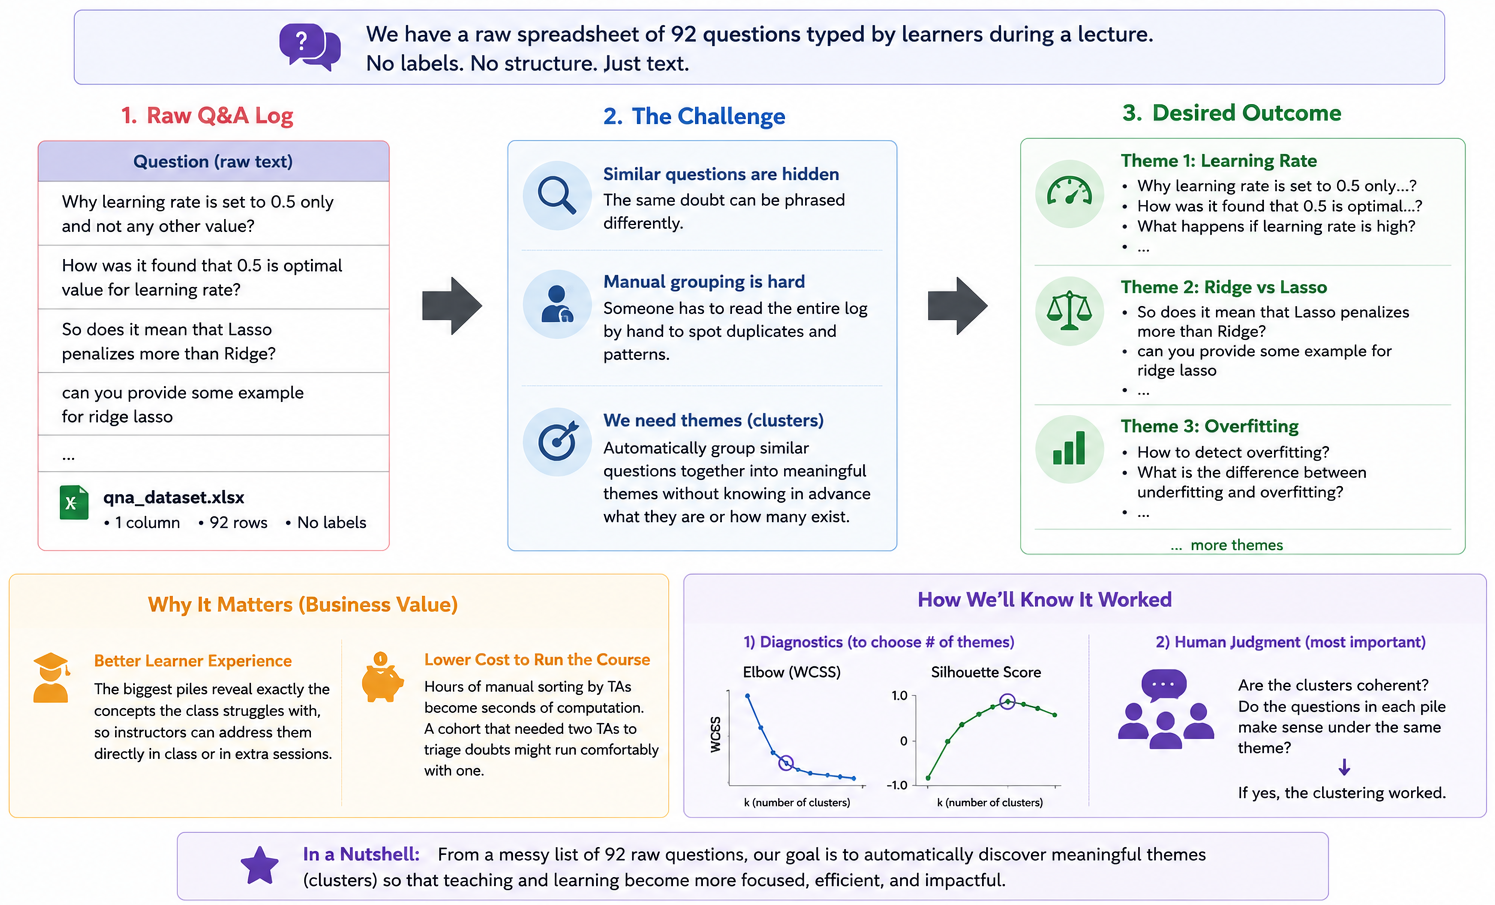

**The journey:**

| Step | What we do | Why |
|---|---|---|
| **1. Load & inspect** | Read the questions, drop exact duplicates | Understand the raw data before modelling |
| **2. Embed** | Turn each question into a 384-D meaning vector (`all-MiniLM-L6-v2`) | Cluster by **meaning**, not shared words |
| **3. Curse of dimensionality** | See why raw 384-D distances stop being informative | Motivate reducing the dimensions first |
| **4. PCA** | Compress to the components holding ~90% of the variance | Cut noise and restore trustworthy distances |
| **5. Choose `k`** | K-Means guided by the **elbow** and **silhouette** | Pick the number of themes in a principled way |
| **6. Reveal themes** | Fit the final K-Means and print each question group | The payoff: a grouped, answer-once sheet |

---


## Setup



In [10]:
%pip install -q sentence-transformers openpyxl

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer

## 1: Load & inspect the data

Before modelling anything, always *look* at the raw data: how many rows, are there
duplicates, how long are the questions?


In [11]:
df = pd.read_excel("qna_dataset.xlsx")

# Drop exact duplicate questions they would bias clusters toward repeated text.
df = df.drop_duplicates().reset_index(drop=True)
questions = df["Question"].astype(str).tolist() # converting pandas series to list

print(f"Number of unique questions : {len(questions)}")
print(f"Average length (characters): {int(np.mean([len(q) for q in questions]))}")
print(f"Shortest / longest         : {min(map(len, questions))} / {max(map(len, questions))} chars\n")

print("A few examples:")
for q in questions[:10]:
    print("  •", q)

Number of unique questions : 92
Average length (characters): 93
Shortest / longest         : 14 / 372 chars

A few examples:
  • Hello Sir, I ddin't get why there are only 2 Inputs, x1 and x2, not more, did the research identified that
  • I didn't understand the difference in calculation between the AND and OR logic? The calculation to arrive at the answer was same. Could you elaborate a bit?
  • Sir, how sigma ri * wi related to vector products in real life significance?
  • Does synapses carry the weights?
  • Is it necessary to remember all these formulas or just concept is enough?
  • Sir, these concepts are on neural network, just to be clear I've not sent a wrong session link, is this session about Supervised learning and logistic regression
  • so the threshold w' is the constant that comes in picture in linear regression.
  • why Transpose?
  • W = determines how important a feature is right?
  • So does it mean bias is independent of the input and adjusts the outcome to make 

## 2: From words to vectors — sentence embeddings

A computer cannot cluster text directly clustering works on **numbers**. So our
first job is to turn each question into a vector (a list of numbers). The *way* we do
this decides whether the whole pipeline succeeds or fails.


A **sentence embedding model** is a neural network trained on billions of sentences to
map text into a fixed length vector of real numbers (here, **384 numbers per
question**) such that *sentences with similar meaning land near each other* even when
they use completely different words. It has effectively learned that "learning rate"
and "step size" point in almost the same direction.

We use **`all-MiniLM-L6-v2`**, a small, fast, well tested model. Two details matter:

- **The vector is dense.** Every one of the 384 numbers carries information
- **We normalise each vector to length 1.** After this, the *distance* between two
  vectors is just a re expression of the **cosine similarity** of their meanings, which
  is the quantity we actually care about.




In [12]:
# Load the pre-trained model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Encode every question. normalize_embeddings=True scales each vector to length 1,
# so Euclidean distance and cosine similarity become two views of the same thing.
embeddings = model.encode(
    questions,
    normalize_embeddings=True,
    show_progress_bar=True,
)

print("\nEmbedding matrix shape:", embeddings.shape, " (questions × dimensions)")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/3 [00:00<?, ?it/s]


Embedding matrix shape: (92, 384)  (questions × dimensions)
